## Lab #3: Asking a statistical question

This week we are going to concentrate on asking a statistical question.
This process almost always consists of 3+ steps:

1.  Writing down in words *very precisely* what question you are trying
    to ask.
2.  Translating the precise english question into a mathematical
    expression. This often includes determining the pdf of the
    background (possibly including trials), and the to integral to do to
    obtain a probability.
3.  Coverting the probability into equivalent sigma

So in this lab we will assume that we know the form of the signal-free
background distribution (determining a distribution from data will be
next week's lab). In each of our three examples, your task will be to
state the statistical question, convert it to math, then perform the
associated analyses.

## Problem 1

In our first example we are looking at the temperature reading
(meta-data) associated with an experiment. For the experiment to work
reliably, the temperature should be at around 12 Kelvin, and if we look
at the data it is mostly consistent with 12 Kelvin to within the 0.4
degree precision of the thermometry and the thermal control system
(standard deviation). However, there are times when the thermal control
system misbehaved and the temperature was not near 12 K, and in addition
there are various glitches in the thermometry that give anomalously high
and low readings (the reading does not match the real temperature). We
definitely want to identify and throw out all the data when the thermal
control system was not working (and the temperature was truly off from
nominal). While it is possible to have an error in the thermometry such
that the true temperature was fine, and we just had a wonky reading, in
an abundance of caution we want to throw those values out too.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats

#this sets the size of the plot to something useful
plt.rcParams["figure.figsize"] = (20,15)

To make this a bit concrete, we will simulate a little data. Start by
simulating 100k 'good' data points assuming Gaussian fluctations, and
because we are playing god adding the following 'bad' datapoints: {10.,
10.3, 2.1, 0., 0., 15.6, 22.3, 12.7}

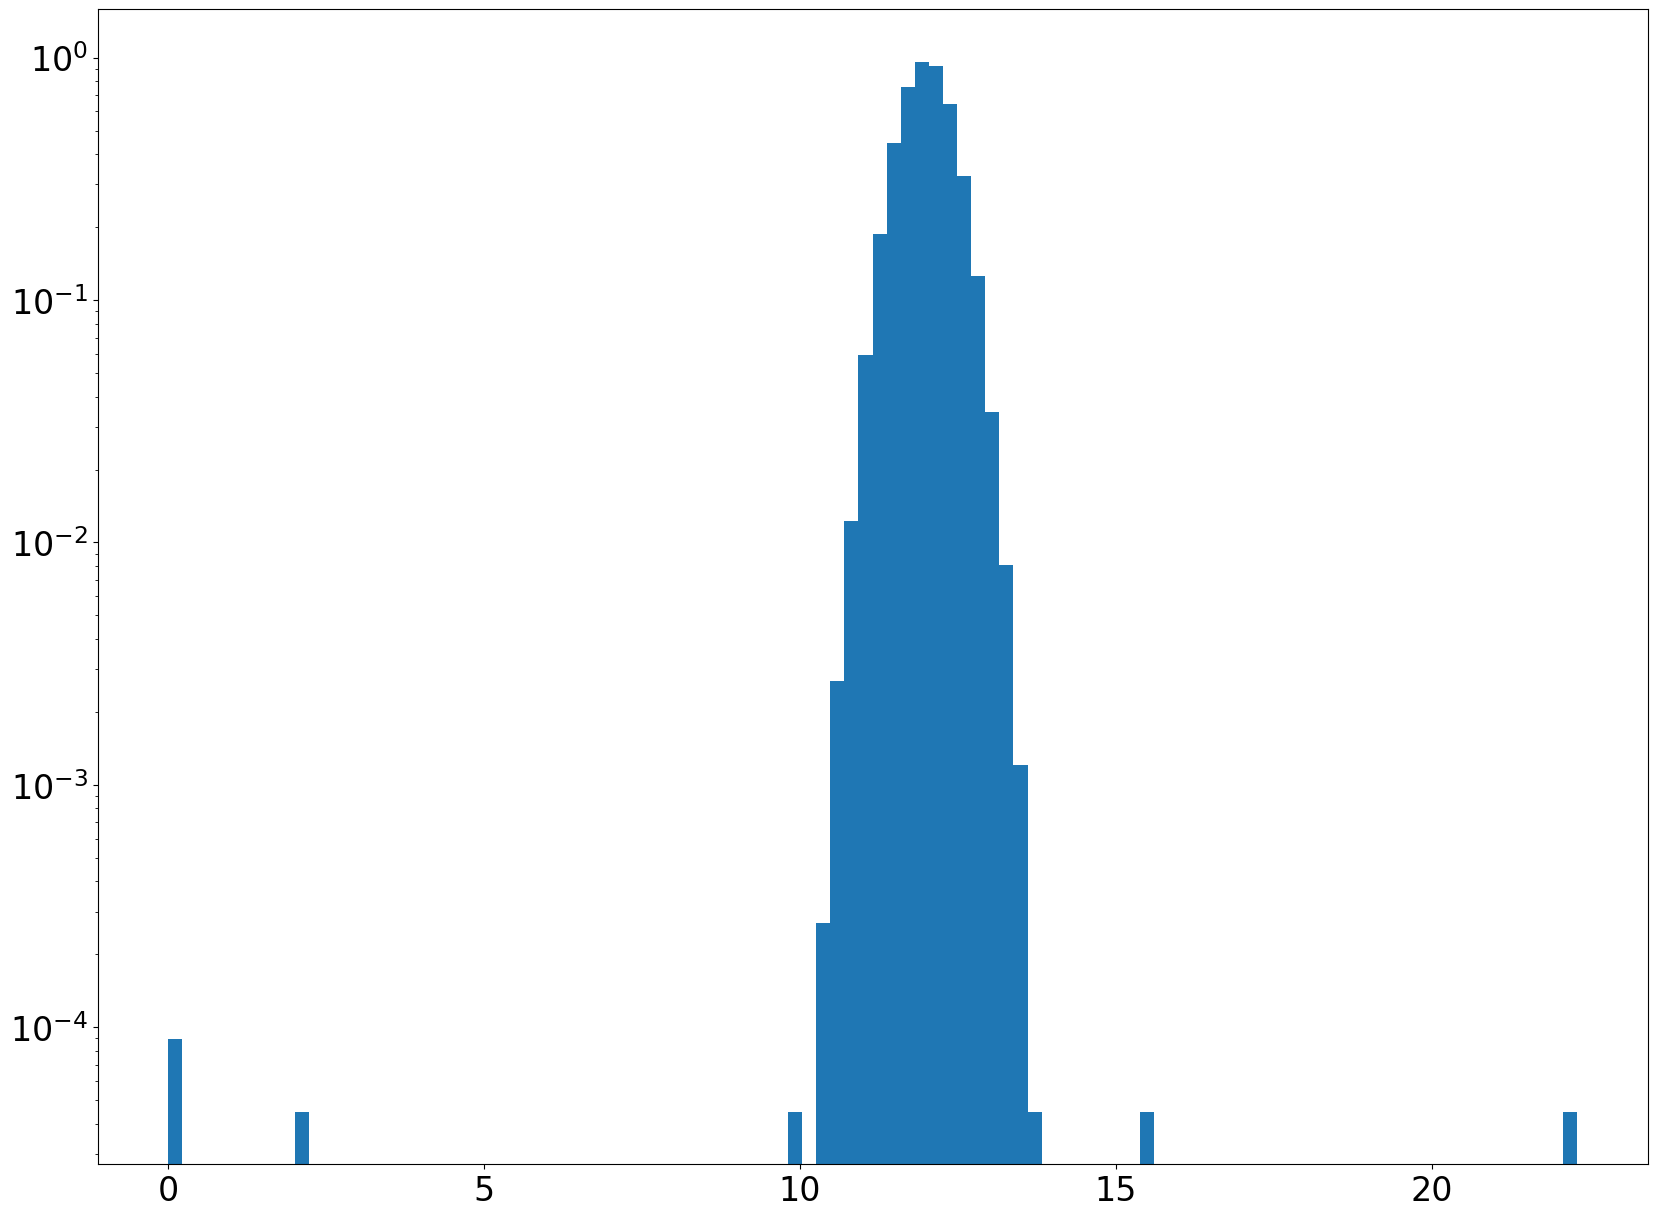

In [9]:
d = np.append(stats.norm.rvs(loc = 12., scale = 0.4, size = 100000), [10., 10.3, 2.1, 0., 0., 15.6, 22.3, 12.7])
fig, ax = plt.subplots(1, 1)
ax.hist(d,100, density=True)
plt.tick_params(labelsize = 24)
plt.yscale('log')
plt.show()

A) So our goal is to identify bad data and throw it out.

1.  Start by exploring the data you have created with appropriate plots
2.  State the statistical question in words. Be very clear, and describe
    why you have chosen this statistical question.
3.  Restate your question in math. Be very clear.
4.  Apply your statistical test and construct a truth table.

|                | True T | Bad T |
|----------------|--------|-------|
| Your Test Good |        |       |
| Your Test Bad  |        |       |

The idea is how often you kept the known good data (True T & Your Test
Good), how often you correctly discarded bad data (Bad T & Your Test
Bad), and how often mistakes were made of either omission or commission
(off diagonals).

The statistical question here is "Given the underlying distribution as described above, which and how much data is outside of our expectation up to some threshold?" To restate it in math, we label a data point x bad if:

$$ |x - \mu| > 5\sigma \rightarrow |x - 12| > 2$$

The rest are, by deduction, going to be labeled as true.

In [14]:
bad = []
for x in d:
    if abs(x - 12) > 2:
        bad.append(x)
goodTrue = 0
goodFalse = 0
badTrue = 0
badFalse = 0
bads = [10., 10.3, 2.1, 0., 0., 15.6, 22.3, 12.7]
for y in bads:
    if y in bad:
        badFalse += 1
    else:
        goodFalse += 1
badFalse = (badFalse / len(bads)) * 100
goodFalse = (goodFalse / len(bads)) * 100
for i in range(0, len(d) - len(bads)):
    if d[i] in bad:
        badTrue += 1
    else:
        goodTrue += 1
goodTrue = (goodTrue / (len(d) - len(bads))) * 100
badTrue = (badTrue / (len(d) - len(bads))) * 100
print(f"The % of data that was labeled good that is good: {goodTrue}")
print(f"The % of data that was labeled good that is bad: {goodFalse}")
print(f"The % of data that was labeled bad that is good: {badTrue}")
print(f"The % of data that was labeled bad that is bad: {badFalse}")

The % of data that was labeled good that is good: 100.0
The % of data that was labeled good that is bad: 37.5
The % of data that was labeled bad that is good: 0.0
The % of data that was labeled bad that is bad: 62.5


B) How does the number of omissions, where you threw out good data,
depend on the statistical threshold you chose and is it a predictable
quantity?

It is simply the number of data points that lie outside of the 5-sigma threshold. This comes from the intuition that a higher threshold corresponds to a smaller number of good points being thrown out (and vice verse, I throw out more good poitns if I lower the threshold). The fraction of these points (and therefore the percentage) can be predicted by adding the CDF corresponding to -5-sigma and the SF corresponding to +5-sigma.

C) Are there mistakes of commission (bad data getting in)? If yes, are
they avoidable and how do they depend on your statistical threshold?

Yes, there are mistakes of comission (37.5% in our test from above), and they would be more avoidable if we lowered the the statistical threshold and therefore throw out more of the bad points. So they follow the same relationship that the good points do, it just depends on how far out the outliers are.

## Problem 2

In this example we will be looking for asteroids. If we look at the
alignment of stars on subsequent images, they don't perfectly align due
to atmospheric and instrumental effects (even ignoring proper motion).
The resulting distribution is two dimensional, and for this lab let's
assume it is a 2D Gaussian with 1 arcsecond RMS. Or said another way, if
I histogram how far all the (stationary) stars appear to have moved I
get something like:

<>:9: SyntaxWarning: invalid escape sequence '\D'
<>:10: SyntaxWarning: invalid escape sequence '\D'
<>:9: SyntaxWarning: invalid escape sequence '\D'
<>:10: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_485/2121784878.py:9: SyntaxWarning: invalid escape sequence '\D'
  plt.ylabel("$\Delta$y arcseconds", fontsize = 18)
/tmp/ipykernel_485/2121784878.py:10: SyntaxWarning: invalid escape sequence '\D'
  plt.xlabel("$\Delta$x arcseconds", fontsize = 18)


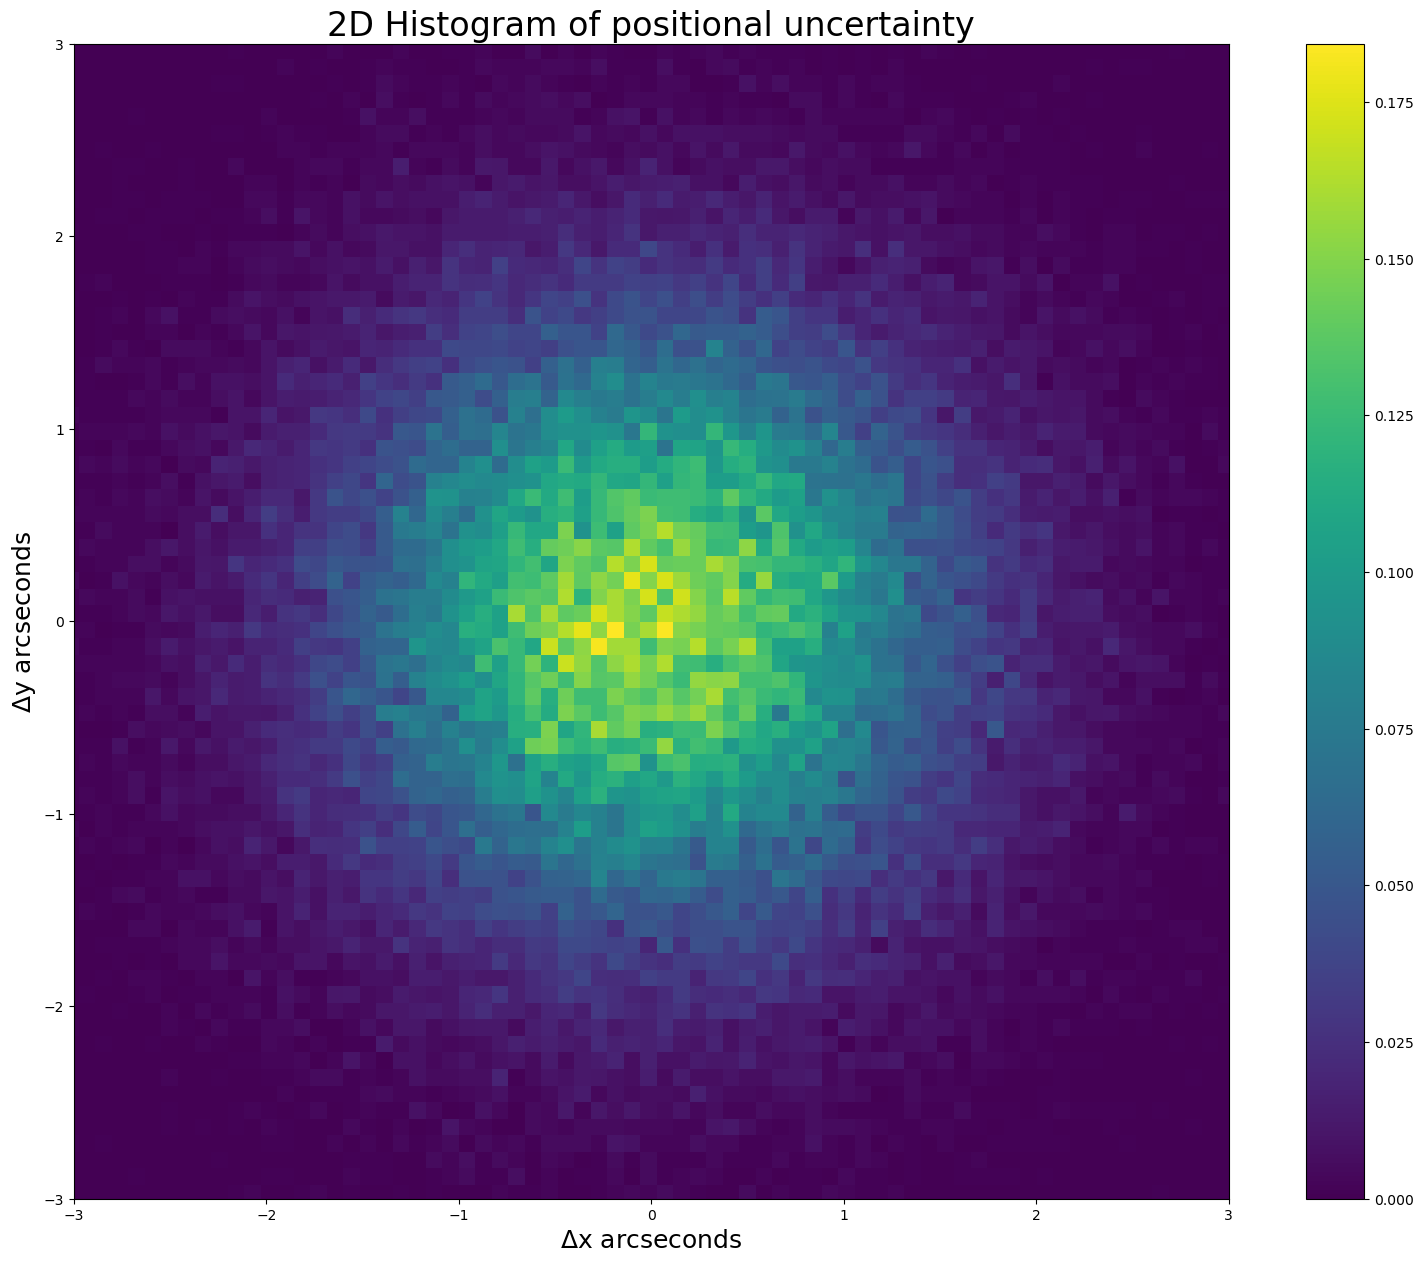

In [19]:
a = np.vstack((stats.norm.rvs( scale = 1, size = 100000), stats.norm.rvs( scale = 1, size = 100000)))
a.shape
fig, ax = plt.subplots(1, 1)
h = ax.hist2d(a[0,:],a[1,:],bins=100, density=True);
ax.set_aspect('equal', 'box')
plt.xlim([-3 , 3])
plt.ylim([-3 , 3])
plt.title("2D Histogram of positional uncertainty", fontsize = 24)
plt.ylabel("$\Delta$y arcseconds", fontsize = 18)
plt.xlabel("$\Delta$x arcseconds", fontsize = 18)
plt.colorbar(h[3], ax=ax)

If I have a potential asteroid, it will have some true movement between
the images. We would like a '5 sigma' detection of movement. What is
that distance in arcseconds?

1.  What is the question in words?
2.  What is the question in math? [Hint: Come up with an analytic
    description of your pdf(). The Blue Book may be helpful here.]
3.  What distance in arcseconds represents a 5 sigma detection of
    motion?

The statistical question here would be "What amount of movement corresponds to a statistically significant (a 5-sigma movement) measurement?" The way to formulate this is first noting that a 5-sigma observation corresponds to a probability (CDF) of 0.9999997. Notice that x and y are uncorrelated and let d be the 5-sigma distance and so we have that:
$$ \mathbb{P}(d - \sqrt{x^2 + y^2} > 0) = \int_{-d} ^ d \int_{-\sqrt{d - y^2}} ^ {\sqrt{d - y^2}} \frac{1}{2\pi}\exp{(-\frac{x^2 + y^2}{2})} dxdy = \int_{0} ^ {2\pi} \int_{0} ^ {d} \frac{1}{2\pi}r\exp{(-\frac{r^2}{2})} drd\theta = \int_{0} ^ {d} r\exp{(-\frac{r^2}{2})} dr = 0.9999997 $$
Notice that once we'd converted to polar coordinates, the CDF integral is that of a rayleigh distribution with respect to r (the distance from the origin) with scale 1. We can use the library for rayleigh to find the 5-sigma ppf, and we get that:

In [18]:
cdf = stats.norm.cdf(5)
distance = stats.rayleigh.ppf(cdf, scale=1)
print(f"The 5-sigma distance is: {round(distance, 2)}")

The 5-sigma distance is: 5.49


## Problem 3

As we discussed in class, one of the key backgrounds for gamma-ray
telescopes are cosmic rays. Cosmic rays are charged particles—usually
protons or electrons but can include atomic nuclei such a alpha
particles (helium) or iron. Because of their charge cosmic rays spiral
in the magnetic field of the galaxy. From the perspective of the Earth
they appear to be coming uniformly from all directions like a high
energy gas, and the direction the cosmic ray is travelling when it
reaches the Earth tells us nothing about where it came from because we
don't know what tortured path it has taken through the galaxy to reach
us. However, at trillion electron volt energies and above, the spiral
loops are fairly big and the sun and the moon will block cosmic rays.
This means the sun and the moon appear as holes in the cosmic ray sky
(cosmic rays from that direction are absorbed).

Assume in a moon sized patch on the sky we normally have a cosmic ray
rate of 1 cosmic ray per minute (arrivals are random in time). If we can
observe where the moon is for 8 hours per night (not too close to the
horizon) and we observe for 15 days and see 6800 cosmic rays, what is
the signficance of our moon shadow detection?

As always:

1.  What is the question in words?
2.  Translate the question to math, describing both the expected
    background pdf() and the integral you need to do.
3.  Convert to sigma.

There are some unique aspects to this problem. Make sure you explore
them in your explanation.

The statistical question is "Does observing 6800 cosmic rays incident from this patch over 15 days correspond to (with high likelihood), the moon blocking cosmic rays? Is our detector working correctly when we point it at the moon?" Assuming that the cosmic ray background follows a poisson distibution at a rate of 1 ray per minute, then the background distribution over 7200 minutes (1 * 60 * 8 * 15) is also poisson with rate 7200. the PDF is:

$$ f(x) = \frac{7200^x \times e^{-\lambda}}{x!}$$

And the sum we need to do corresponds to finding the probability we witness at most 6800 cosmic rays over this time frame:

$$ \mathbb{P}(x \le 6800) = \sum _ 0 ^ {6800} f(x) \approx \int _ 0 ^ {6800} f(x)dx $$

And we simply invert it to get the sigma.

In [27]:
prob = stats.poisson.cdf(6800, mu = 7200)
sigma = stats.norm.ppf(prob)
print(f"Our observation is a {round(sigma, 2)}-sigma one.")

Our observation is a -4.75-sigma one.
